# Домашнее задание 7. Кластерный анализ экспортных рынков

**Оценивание.** `w7_hw.ipynb` весит 50% оценки. `w7_hw.tex` также весит 50% оценки. Максимальный балл за домашнее задание составляет 10 баллов.
**Пояснение к разбалловке.** В предмете нет официального деления на уровни сложности. Цвета лишь помогают ориентироваться в заданиях. За все пункты синего уровня можно получить максимум 5 баллов из 10. Пункты синего и красного уровней дают максимум 7 баллов из 10. Пункты всех трёх уровней дают максимум 10 баллов из 10. Максимальный балл за домашнее задание составляет 10 баллов. Бонусный пункт 3г даёт 1 дополнительный балл чёрного уровня, но итоговый балл за домашнее задание всё равно не может превышать 10.

В этом блокноте ты выполняешь только техническую часть. Загрузи данные, подготовь признаки, построй кластеры, таблицы и графики. Интерпретацию, аргументы и итоговый вывод пиши в `w7_hw.tex`, ссылаясь на результаты этого блокнота.

Ты работаешь с одним российским экспортным товаром команды на уровне HS4 или HS6. Не нужно повторять паспорт товара из домашнего задания 3 и не нужно подгонять выводы под пример с мороженым.

## Для работы тебе пригодятся

Лонгрид недели 7 нужен как справочник по стандартизации, евклидову расстоянию, методу k-средних, WCSS и интерпретации кластеров. Семинар показывает ту же последовательность на данных о мороженом.

В этом домашнем задании ты подготовишь пространство признаков, построишь кластеры и сопоставишь типы импортных рынков. Если будет непонятно, что делать в конкретном блоке, вернись к соответствующему разделу лонгрида и к семинарским ячейкам с похожим расчётом.

Перенеси из предыдущей домашней работы только параметры товара, необходимые для загрузки данных. Готовые функции только загружают данные и строят карту. Подготовку матрицы признаков, стандартизацию, обучение моделей, проверку числа кластеров и итоговые таблицы выполни самостоятельно.


In [1]:
# Запусти эту ячейку перед выполнением заданий
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Polygon as MplPolygon
import requests

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

pd.options.display.float_format = "{:,.3f}".format

OEC_BASE_URL = "https://api-v2.oec.world/tesseract"
TRADE_CUBE = "trade_i_baci_a_17"
WORLD_MAP_URL = (
    "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/"
    "master/geojson/ne_110m_admin_0_countries.geojson"
)

def load_oec_data(drilldowns, include=None, measures="Trade Value", limit=50000):
    params = {
        "cube": TRADE_CUBE,
        "drilldowns": ",".join(drilldowns),
        "measures": measures,
        "locale": "en",
        "parents": "false",
        "limit": f"{limit},0",
    }
    if include:
        params["include"] = ";".join(include)
    response = requests.get(
        f"{OEC_BASE_URL}/data.jsonrecords",
        params=params,
        timeout=120,
    )
    response.raise_for_status()
    table = pd.DataFrame(response.json()["data"])
    if table.empty:
        raise ValueError("OEC вернул пустую таблицу. Проверь код и уровень HS.")
    return table, response.url

def load_wdi_indicator(indicator, value_name, start_year=2020, end_year=2025, scale=1):
    url = f"https://api.worldbank.org/v2/country/all/indicator/{indicator}"
    response = requests.get(
        url,
        params={"format": "json", "date": f"{start_year}:{end_year}", "per_page": 20000},
        timeout=120,
    )
    response.raise_for_status()
    payload = response.json()
    rows = [
        {
            "ISO3": item["countryiso3code"],
            "Год показателя": int(item["date"]),
            value_name: item["value"] / scale,
        }
        for item in payload[1]
        if item["countryiso3code"] and item["value"] is not None
    ]
    return pd.DataFrame(rows), response.url

def build_market_features(
    product_key,
    product_level="HS4",
    years_back=4,
    country_iso=None,
    min_countries=10,
):
    trade, trade_url = load_oec_data(
        ["Year", "Importer Country", product_level],
        [f"{product_level}:{product_key}"],
    )
    trade["ISO3"] = trade["Importer Country ID"].str[-3:].str.upper()
    trade["Страна"] = trade["Importer Country"]
    if country_iso is not None:
        trade = trade.loc[trade["ISO3"].isin(country_iso)].copy()
    trade = trade.groupby(["Year", "ISO3", "Страна"], as_index=False)["Trade Value"].sum()

    years = sorted(trade["Year"].unique())
    if len(years) < 2:
        raise ValueError("Для расчёта роста недостаточно лет.")
    last_year = years[-1]
    first_year = years[max(0, len(years) - years_back - 1)]
    span = max(1, last_year - first_year)

    first = (
        trade.loc[trade["Year"].eq(first_year), ["ISO3", "Trade Value"]]
        .rename(columns={"Trade Value": "Первый импорт"})
    )
    last = (
        trade.loc[trade["Year"].eq(last_year), ["ISO3", "Страна", "Trade Value"]]
        .rename(columns={"Trade Value": "Последний импорт"})
    )
    markets = first.merge(last, on="ISO3")
    markets = markets.loc[
        (markets["Первый импорт"] > 0) & (markets["Последний импорт"] > 0)
    ].copy()
    markets["Импорт товара, млн долл"] = markets["Последний импорт"] / 1e6
    markets["Рост импорта, %"] = (
        (markets["Последний импорт"] / markets["Первый импорт"]) ** (1 / span) - 1
    ) * 100

    income, income_url = load_wdi_indicator(
        "NY.GDP.PCAP.CD", "Доход на душу, тыс долл", scale=1000
    )
    income = (
        income.sort_values("Год показателя")
        .drop_duplicates("ISO3", keep="last")
        [["ISO3", "Год показателя", "Доход на душу, тыс долл"]]
    )
    markets = markets.merge(income, on="ISO3", how="inner")
    income_years = sorted(markets["Год показателя"].unique())
    if len(income_years) == 1:
        income_note = str(income_years[0])
    else:
        income_note = f"{income_years[0]}–{income_years[-1]}"
    columns = [
        "ISO3", "Страна", "Импорт товара, млн долл",
        "Рост импорта, %", "Доход на душу, тыс долл", "Год показателя",
    ]
    markets = markets[columns].sort_values("ISO3").reset_index(drop=True)
    if len(markets) < min_countries:
        raise ValueError(
            f"После объединения осталось {len(markets)} стран: "
            f"нужно не меньше {min_countries}."
        )
    note = f"OEC/BACI: {first_year}–{last_year}; World Bank: {income_note}."
    return markets, note, {"OEC": trade_url, "World Bank": income_url}

def load_market_features(
    product_key,
    product_level="HS4",
    years_back=4,
    country_iso=None,
    min_countries=10,
):
    """Загружает живые данные OEC/BACI и World Bank без резервной таблицы"""
    return build_market_features(
        product_key=product_key,
        product_level=product_level,
        years_back=years_back,
        country_iso=country_iso,
        min_countries=min_countries,
    )

def load_world_geojson(geojson_path=None):
    candidates = []
    if geojson_path is not None:
        candidates.append(Path(geojson_path))
    candidates.extend(
        [
            Path("Export/w7/seminar/data/ne_110m_admin_0_countries.geojson"),
            Path("../seminar/data/ne_110m_admin_0_countries.geojson"),
        ]
    )
    for candidate in candidates:
        if candidate.exists():
            return json.loads(candidate.read_text(encoding="utf-8"))
    response = requests.get(WORLD_MAP_URL, timeout=120)
    response.raise_for_status()
    return response.json()

def show_cluster_map(
    data,
    geojson_path=None,
    location_column="ISO3",
    cluster_column="Кластер",
    title="Кластеры стран",
):
    world = load_world_geojson(geojson_path)
    cluster_by_iso = (
        data[[location_column, cluster_column]]
        .drop_duplicates(location_column)
        .set_index(location_column)[cluster_column]
    )
    labels = sorted(cluster_by_iso.dropna().unique())
    palette = plt.get_cmap("tab10")
    colors = {label: palette(i % 10) for i, label in enumerate(labels)}

    fig, ax = plt.subplots(figsize=(13, 7))
    ax.set_facecolor("#dfeef5")
    for feature in world["features"]:
        iso3 = feature["properties"].get("ADM0_A3")
        facecolor = colors.get(cluster_by_iso.get(iso3), "#eeeeee")
        geometry = feature.get("geometry")
        if geometry is None:
            continue
        if geometry["type"] == "Polygon":
            polygons = [geometry["coordinates"]]
        elif geometry["type"] == "MultiPolygon":
            polygons = geometry["coordinates"]
        else:
            continue
        for polygon in polygons:
            ax.add_patch(
                MplPolygon(
                    polygon[0], closed=True, facecolor=facecolor,
                    edgecolor="white", linewidth=0.35,
                )
            )

    handles = [
        Patch(facecolor=colors[label], edgecolor="white", label=f"Кластер {label}")
        for label in labels
    ]
    ax.legend(handles=handles, title="Группа", loc="lower left")
    ax.set_xlim(-180, 180)
    ax.set_ylim(-60, 90)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(title)
    ax.axis("off")
    plt.show()

map_candidates = [
    Path("Export/w7/seminar/data/ne_110m_admin_0_countries.geojson"),
    Path("../seminar/data/ne_110m_admin_0_countries.geojson"),
]
WORLD_GEOJSON_PATH = next((path for path in map_candidates if path.exists()), None)

# Перенеси из предыдущей домашней работы параметры выбранного товара
# Товар команды тот же, что в прошлых ДЗ: фанера, HS4 4412 (версия HS 2017).
# В этом формате запросов OEC перед кодом стоит номер раздела HS: 9 — древесина и изделия из неё.
PRODUCT_LEVEL = "HS4"
PRODUCT_KEY = "94412"
SAMPLE_SIZE = 30       # Не менее 20 стран
PAIR_ISO = ["KOR", "IND", "SAU"]  # три рынка, которые мы выделили в прошлых работах

## **[Синий, 3 балла]** Задание 1. Подготовка данных и пространства признаков

### **[Синий, 1 балл]** Пункт 1а. Таблица импортных рынков

Начни с границ своего исследования. Загрузи данные выбранного товара вызовом `load_market_features()`, оставь не менее 20 стран с крупнейшим импортом и сохрани их в `markets_sample`. Зафиксируй правило отбора, выведи период данных, число стран и пять первых строк таблицы. По этим результатам в TeX ты определишь, какую совокупность рынков описывает дальнейший анализ и к каким странам нельзя относить полученные выводы. Паспорт товара повторно составлять и выводить не нужно.

**Что получить на выходе.** Таблицу `markets_sample` с кодом и названием страны, импортом, ростом и доходом; строку с периодом данных и числом стран.

**Пример вывода.** `OEC/BACI: [годы]; World Bank: [год]. Стран в выборке: [число]`.


In [2]:
# Загрузи данные, собери markets_sample и выведи период и число стран
markets_all, data_note, data_urls = load_market_features(PRODUCT_KEY, PRODUCT_LEVEL)

# Правило отбора: SAMPLE_SIZE стран с наибольшим импортом фанеры в последнем году
markets_sample = markets_all.sort_values("Импорт товара, млн долл", ascending=False)
markets_sample = markets_sample.head(SAMPLE_SIZE).reset_index(drop=True)

sample_share = markets_sample["Импорт товара, млн долл"].sum() / markets_all["Импорт товара, млн долл"].sum()
print(f"Товар: фанера, {PRODUCT_LEVEL} 4412, классификация HS 2017 (ключ OEC {PRODUCT_KEY})")
print(f"{data_note} Стран в выборке: {len(markets_sample)}")
print(f"Стран с данными и по торговле, и по доходу: {len(markets_all)}")
print(f"Отобранные {len(markets_sample)} стран дают {sample_share:.1%} импорта фанеры по всем этим странам")
print(f"Самый маленький импорт в выборке: {markets_sample['Импорт товара, млн долл'].min():.1f} млн долл. ({markets_sample.iloc[-1]['ISO3']})")
income_years = markets_sample["Год показателя"].value_counts().sort_index()
print("Год дохода в выборке (год: число стран):", ", ".join(f"{year}: {count}" for year, count in income_years.items()))
print("Строка World Bank выше описывает все 202 страны, в самой выборке доход за 2024–2025 годы")
display(markets_sample.head())
print("Запросы:")
for name, url in data_urls.items():
    print(f"  {name}: {url}")

Товар: фанера, HS4 4412, классификация HS 2017 (ключ OEC 94412)
OEC/BACI: 2020–2024; World Bank: 2020–2025. Стран в выборке: 30
Стран с данными и по торговле, и по доходу: 202
Отобранные 30 стран дают 83.8% импорта фанеры по всем этим странам
Самый маленький импорт в выборке: 116.8 млн долл. (TUR)
Год дохода в выборке (год: число стран): 2024: 1, 2025: 29
Строка World Bank выше описывает все 202 страны, в самой выборке доход за 2024–2025 годы


,ISO3,Страна,"Импорт товара, млн долл","Рост импорта, %","Доход на душу, тыс долл",Год показателя
0,USA,United States,"3,086.510",2.275,90.027,2025
1,JPN,Japan,"1,124.236",-1.322,35.951,2025
2,DEU,Germany,968.509,3.148,60.496,2025
3,KOR,South Korea,689.141,-3.189,36.227,2025
4,GBR,United Kingdom,662.014,5.203,57.602,2025


Запросы:
  OEC: https://api-v2.oec.world/tesseract/data.jsonrecords?cube=trade_i_baci_a_17&drilldowns=Year%2CImporter+Country%2CHS4&measures=Trade+Value&locale=en&parents=false&limit=50000%2C0&include=HS4%3A94412
  World Bank: https://api.worldbank.org/v2/country/all/indicator/NY.GDP.PCAP.CD?format=json&date=2020%3A2025&per_page=20000


**Что видим.** Берём 30 стран с наибольшим импортом фанеры в 2024 году: от США (3,09 млрд долл.) до Турции (117 млн). Вместе они дают 83,8% импорта по всем 202 странам, где есть и торговля, и доход. Рост считаем среднегодовым за 2020–2024 годы, доход берём за последний доступный год. Выводы относятся только к крупным рынкам, про маленьких покупателей фанеры эта выборка ничего не говорит. И ещё: сюда попали ЕС, Великобритания и США, куда российской фанере сейчас путь закрыт или сильно затруднён, это надо помнить при чтении кластеров.

### **[Синий, 1 балл]** Пункт 1б. Диагностика признаков

Прежде чем рассчитывать расстояния, проверь, как устроены выбранные признаки. Для импорта, роста импорта и дохода на душу населения построй описательную статистику через `describe().T`, отдельно посчитай пропуски и найди крайние значения. Сохрани очищенную таблицу в `analysis_data` и проверь, что в ней осталось не менее 20 стран. Эти таблицы понадобятся тебе, чтобы самостоятельно решить, какие наблюдения требуют отдельного объяснения.

**Что получить на выходе.** Список `RAW_FEATURES`, таблицы `diagnostics` и `missing_values`, очищенную таблицу `analysis_data`.

**Пример вывода.**

| Признак | Count | Mean | Std | Min | 50% | Max | Пропуски |
|---|---:|---:|---:|---:|---:|---:|---:|
| [Признак] | [Число] | [Значение] | [Значение] | [Значение] | [Значение] | [Значение] | [Число] |


In [3]:
# Создай RAW_FEATURES, diagnostics, missing_values и analysis_data.
RAW_FEATURES = ["Импорт товара, млн долл", "Рост импорта, %", "Доход на душу, тыс долл"]

missing_values = markets_sample[RAW_FEATURES].isna().sum().rename("Пропуски")
diagnostics = markets_sample[RAW_FEATURES].describe().T.join(missing_values)
# Стандартные отклонения в разных единицах напрямую не сравнить, поэтому добавляем
# коэффициент вариации: разброс относительно среднего
diagnostics["Коэф. вариации"] = diagnostics["std"] / diagnostics["mean"]
display(diagnostics)

# Крайние значения: у кого минимум и максимум по каждому признаку
extremes = []
for feature in RAW_FEATURES:
    low = markets_sample.loc[markets_sample[feature].idxmin()]
    high = markets_sample.loc[markets_sample[feature].idxmax()]
    extremes.append({
        "Признак": feature,
        "Минимум": f"{low['ISO3']} ({low[feature]:.1f})",
        "Максимум": f"{high['ISO3']} ({high[feature]:.1f})",
    })
display(pd.DataFrame(extremes))

# Выбросы по правилу полутора межквартильных размахов. Не удаляем их, просто отмечаем.
outliers = []
for feature in RAW_FEATURES:
    q1 = markets_sample[feature].quantile(0.25)
    q3 = markets_sample[feature].quantile(0.75)
    iqr = q3 - q1
    far = markets_sample[(markets_sample[feature] < q1 - 1.5 * iqr) | (markets_sample[feature] > q3 + 1.5 * iqr)]
    outliers.append({"Признак": feature, "Страны за пределами 1,5 IQR": ", ".join(far["ISO3"]) or "нет"})
display(pd.DataFrame(outliers))

analysis_data = markets_sample.dropna(subset=RAW_FEATURES).reset_index(drop=True)
print(f"Стран после очистки: {len(analysis_data)}; не меньше 20: {len(analysis_data) >= 20}")

,count,mean,std,min,25%,50%,75%,max,Пропуски,Коэф. вариации
"Импорт товара, млн долл",30.000,457.116,552.304,116.835,218.795,281.575,447.390,"3,086.510",0,1.208
"Рост импорта, %",30.000,6.594,8.533,-12.901,2.493,4.780,11.799,32.602,0,1.294
"Доход на душу, тыс долл",30.000,41.527,29.037,2.702,13.869,40.968,60.687,114.769,0,0.699


,Признак,Минимум,Максимум
0,"Импорт товара, млн долл",TUR (116.8),USA (3086.5)
1,"Рост импорта, %",VNM (-12.9),IND (32.6)
2,"Доход на душу, тыс долл",IND (2.7),CHE (114.8)


,Признак,"Страны за пределами 1,5 IQR"
0,"Импорт товара, млн долл","USA, JPN, DEU"
1,"Рост импорта, %","IND, VNM"
2,"Доход на душу, тыс долл",нет


Стран после очистки: 30; не меньше 20: True


**Что видим.** Пропусков нет, все 30 стран остаются. Медиана импорта 282 млн долл. (от 117 млн у Турции до 3 087 млн у США), роста — 4,8% в год (от −12,9% у Вьетнама до +32,6% у Индии), дохода — 41,0 тыс. долл. на человека (от 2,7 тыс. в Индии до 114,8 тыс. в Швейцарии). В своих единицах сильнее всего разбросан импорт: стандартное отклонение 552 млн долл. против 8,5 п. п. у роста, поэтому без подготовки расстояния почти целиком определял бы импорт. Относительно среднего разброс у роста и импорта одинаково большой (коэффициенты вариации 1,29 и 1,21), у дохода меньше (0,70). По правилу 1,5 IQR выбиваются США, Япония и Германия по импорту и Индия с Вьетнамом по росту. Их не удаляем: данные по ним настоящие.

### **[Синий, 1 балл]** Пункт 1в. Стандартизация и расстояния

Теперь задай пространство, в котором будут сравниваться рынки. Добавь столбец `Логарифм импорта` по формуле $\ln(1+M_i)$ и используй его вместе с ростом и доходом как три признака `FEATURES`. Стандартизируй матрицу с помощью `StandardScaler`. Для трёх стран из `PAIR_ISO` рассчитай все три попарных евклидовых расстояния. После расчёта вернись к исходным значениям этих стран: в TeX тебе нужно будет объяснить близость и различие рынков через конкретные признаки.

**Что получить на выходе.** Матрицу `z_scores`, проверку её средних и стандартных отклонений, таблицу `pair_distances` из трёх строк.

**Пример вывода.**

| Пара | Расстояние |
|---|---:|
| [ISO3–ISO3] | [Значение] |


In [4]:
# Создай FEATURES и z_scores. Рассчитай pair_distances без цикла по строкам
# Импорт у США в десятки раз больше, чем у большинства стран. Логарифм сжимает этот разрыв,
# иначе расстояния определял бы почти один импорт.
analysis_data["Логарифм импорта"] = np.log1p(analysis_data["Импорт товара, млн долл"])
FEATURES = ["Логарифм импорта", "Рост импорта, %", "Доход на душу, тыс долл"]

scaler = StandardScaler()
z_scores = pd.DataFrame(
    scaler.fit_transform(analysis_data[FEATURES]),
    columns=FEATURES,
    index=analysis_data["ISO3"],
)

z_check = pd.DataFrame({"Среднее": z_scores.mean(), "Ст. отклонение": z_scores.std(ddof=0)})
display(z_check.round(3))

# Три пары считаем векторно: строки первых стран минус строки вторых
pairs = [(PAIR_ISO[0], PAIR_ISO[1]), (PAIR_ISO[0], PAIR_ISO[2]), (PAIR_ISO[1], PAIR_ISO[2])]
left = z_scores.loc[[a for a, b in pairs]].to_numpy()
right = z_scores.loc[[b for a, b in pairs]].to_numpy()
pair_distances = pd.DataFrame({
    "Пара": [f"{a}–{b}" for a, b in pairs],
    "Расстояние": np.sqrt(((left - right) ** 2).sum(axis=1)),
})
display(pair_distances)

# Исходные значения и z-оценки этих стран, чтобы было видно, за счёт чего они близки или далеки
pair_view = analysis_data.set_index("ISO3").loc[PAIR_ISO, RAW_FEATURES]
display(pair_view)
display(z_scores.loc[PAIR_ISO].round(2))

,Среднее,Ст. отклонение
Логарифм импорта,0.000,1.000
"Рост импорта, %",-0.000,1.000
"Доход на душу, тыс долл",-0.000,1.000


,Пара,Расстояние
0,KOR–IND,4.627
1,KOR–SAU,2.184
2,IND–SAU,2.552


,"Импорт товара, млн долл","Рост импорта, %","Доход на душу, тыс долл"
ISO3,,,
KOR,689.141,-3.189,36.227
IND,257.590,32.602,2.702
SAU,401.833,14.038,34.537


,Логарифм импорта,"Рост импорта, %","Доход на душу, тыс долл"
ISO3,,,
KOR,1.020,-1.170,-0.190
IND,-0.330,3.100,-1.360
SAU,0.280,0.890,-0.240


**Что видим.** После стандартизации у всех трёх признаков среднее 0 и стандартное отклонение 1, так что ни один признак не перевешивает из-за своих единиц. Ближе всего Корея и Саудовская Аравия (2,18): доход у них почти одинаковый, 36,2 и 34,5 тыс. долл., а различаются они в основном ростом импорта. Дальше всего Корея и Индия (4,63): у Индии импорт растёт на 32,6% в год против −3,2% у Кореи, а доход в 13 раз ниже.

## **[Синий, 2 балла, красный, 2 балла]** Задание 2. Построение и проверка кластеров

### **[Синий, 1 балл]** Пункт 2а. Решение для трёх кластеров

Построй первое разбиение рынков. Обучи `KMeans` с $k=3$, `n_init=30` и `random_state=42`, добавь метки к таблице `clustered3` и сохрани состав стран каждой группы. Рассчитай число стран и средние исходные признаки кластеров. Отдельно верни центры из стандартизированной шкалы в шкалу признаков методом `inverse_transform()`; значение импорта при этом останется логарифмом. По профилям и составу стран в TeX ты самостоятельно сформулируешь нейтральные названия полученных типов рынков.

**Что получить на выходе.** Таблицу `clustered3`, профиль `profile3` со средними исходными признаками, центры `centers3` с логарифмом импорта, ростом и доходом.

**Пример вывода.**

| Кластер | Стран | Импорт | Рост | Доход |
|---:|---:|---:|---:|---:|
| [Номер] | [Число] | [Значение] | [Значение] | [Значение] |


In [5]:
# Обучи model3. Создай clustered3, profile3 и centers3
model3 = KMeans(n_clusters=3, n_init=30, random_state=42)
raw_labels3 = model3.fit_predict(z_scores)

# Номера кластеров у KMeans случайные. Перенумеруем по убыванию среднего импорта, чтобы номера
# не прыгали при перезапуске. Это только порядок для чтения, а не рейтинг рынков.
clustered3 = analysis_data.copy()
clustered3["Метка KMeans"] = raw_labels3
order3 = clustered3.groupby("Метка KMeans")["Логарифм импорта"].mean().sort_values(ascending=False).index
renumber3 = {old: new for new, old in enumerate(order3, start=1)}
clustered3["Кластер"] = clustered3["Метка KMeans"].map(renumber3)

members3 = clustered3.sort_values("Импорт товара, млн долл", ascending=False).groupby("Кластер")["ISO3"].apply(", ".join)
print("Состав кластеров:")
for cluster, countries in members3.items():
    print(f"  {cluster}: {countries}")

profile3 = clustered3.groupby("Кластер").agg(
    Стран=("ISO3", "count"),
    Импорт=("Импорт товара, млн долл", "mean"),
    Рост=("Рост импорта, %", "mean"),
    Доход=("Доход на душу, тыс долл", "mean"),
)
display(profile3)

centers3 = pd.DataFrame(scaler.inverse_transform(model3.cluster_centers_), columns=FEATURES)
centers3.index = [renumber3[label] for label in range(3)]
centers3.index.name = "Кластер"
centers3 = centers3.sort_index()
centers3["Импорт в центре, млн долл"] = np.expm1(centers3["Логарифм импорта"])  # для наглядности
display(centers3)

Состав кластеров:
  1: USA, JPN, DEU, KOR, GBR, NLD, AUS, FRA, CAN, BEL, CHE
  2: MEX, MYS, SAU, ITA, CHN, ARE, POL, IND, ISR, ESP, TUR
  3: PHL, THA, VNM, EGY, AUT, IRQ, DNK, SWE


,Стран,Импорт,Рост,Доход
Кластер,,,,
1,11,821.936,3.324,63.574
2,11,292.440,15.030,28.880
3,8,181.918,-0.509,28.603


,Логарифм импорта,"Рост импорта, %","Доход на душу, тыс долл","Импорт в центре, млн долл"
Кластер,,,,
1,6.452,3.324,63.574,633.210
2,5.599,15.030,28.880,269.039
3,5.169,-0.509,28.603,174.733


**Что видим.** Кластер 1 — 11 крупных и богатых рынков (США, Япония, Германия, Корея, Великобритания и др.): средний импорт 822 млн долл., рост 3,3% в год, доход 63,6 тыс. долл. Кластер 2 — 11 быстро растущих рынков со средним доходом (Мексика, Саудовская Аравия, Китай, Индия, Турция и др.): импорт 292 млн, рост 15,0%, доход 28,9 тыс. Кластер 3 — 8 стран, где импорт почти не растёт (−0,5% в год). Туда попали и бедные Египет с Филиппинами, и богатые Дания со Швецией, так что эта группа самая разнородная.

### **[Синий, 1 балл]** Пункт 2б. Диаграмма и карта кластеров

Покажи одно и то же разбиение в двух представлениях. На диаграмме рассеяния отложи по оси $x$ импорт в логарифмической шкале, по оси $y$ — рост импорта, цветом обозначь кластер и подпиши ISO3. Затем вызови `show_cluster_map()` и получи карту с заливкой стран по группам. Сопоставь оба графика с таблицей профилей и отметь для будущего текста, что видно и что теряется в каждом представлении.

**Что получить на выходе.** Подписанную диаграмму рассеяния и карту мира с тремя цветами кластеров.


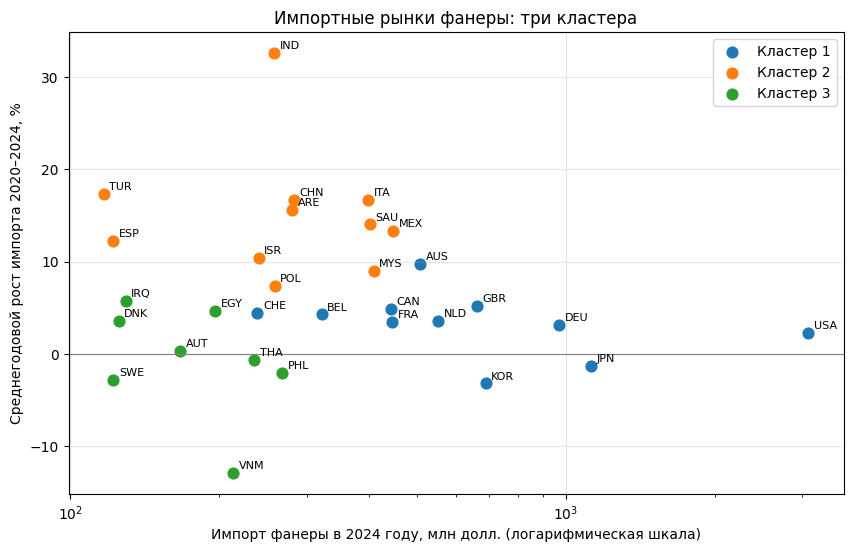

Доход на душу на диаграмме не виден, хотя участвует в расчёте: его показывает только таблица профилей


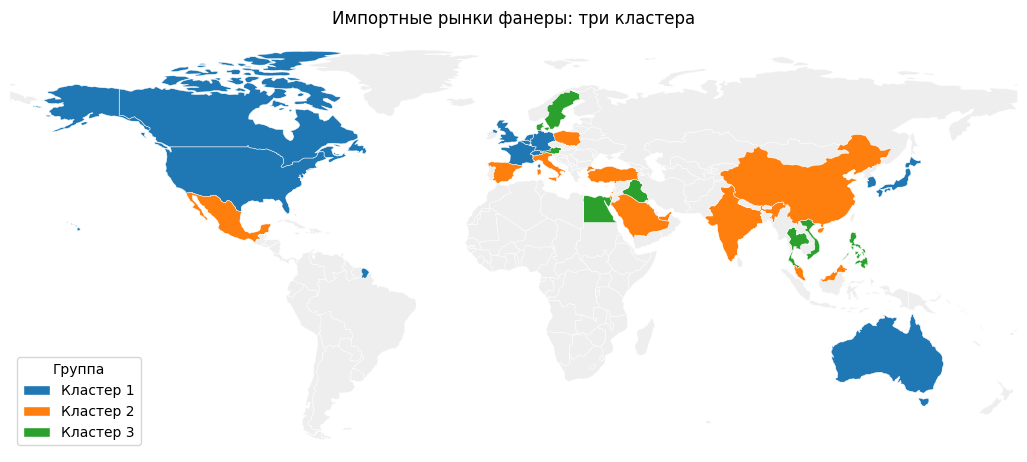

In [6]:
# Построй диаграмму рассеяния и карту clustered3
palette = plt.get_cmap("tab10")  # те же цвета, что на карте: кластер 1 — синий, 2 — оранжевый и т.д.

fig, ax = plt.subplots(figsize=(10, 6))
for i, (cluster, group) in enumerate(clustered3.groupby("Кластер")):
    ax.scatter(group["Импорт товара, млн долл"], group["Рост импорта, %"],
               color=palette(i), s=60, label=f"Кластер {cluster}")
for _, row in clustered3.iterrows():
    ax.annotate(row["ISO3"], (row["Импорт товара, млн долл"], row["Рост импорта, %"]),
                textcoords="offset points", xytext=(4, 3), fontsize=8)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xscale("log")
ax.set_xlabel("Импорт фанеры в 2024 году, млн долл. (логарифмическая шкала)")
ax.set_ylabel("Среднегодовой рост импорта 2020–2024, %")
ax.set_title("Импортные рынки фанеры: три кластера")
ax.grid(alpha=0.3)
ax.legend()
plt.show()
print("Доход на душу на диаграмме не виден, хотя участвует в расчёте: его показывает только таблица профилей")

show_cluster_map(clustered3, WORLD_GEOJSON_PATH, title="Импортные рынки фанеры: три кластера")

**Что видим.** На диаграмме группы делятся в основном по росту: оранжевый кластер наверху, зелёный внизу около нуля, синий справа, где импорт больше. Дохода здесь не видно, поэтому Швейцария и Бельгия кажутся в синем кластере лишними, хотя их туда притянул высокий доход. На карте видна география: синий — Северная Америка, Западная Европа, Япония, Корея и Австралия; оранжевый — Мексика, Ближний Восток, Индия, Китай и часть Южной Европы; зелёный — Юго-Восточная Азия, Египет, Ирак и часть Северной Европы. Зато карта не показывает ни масштаб импорта, ни темп.

### **[Красный, 1 балл]** Пункт 2в. Выбор числа кластеров

Сравни несколько допустимых разбиений, прежде чем выбрать итоговое. Для каждого $k$ от 2 до 6 обучи отдельную модель, сохрани WCSS и средний силуэтный коэффициент и построй два графика. Выбери `SELECTED_K`, повторно обучи итоговую модель и сохрани метки в `final_clustered`. Оставь в таблице все проверенные варианты: в TeX выбор нужно будет обосновать одновременно по значениям критериев и по содержанию групп.

**Что получить на выходе.** Таблицу `validation`, два графика, число `SELECTED_K`, итоговую модель `final_model` и таблицу `final_clustered`.

**Пример вывода.**

| $k$ | WCSS | Силуэт |
|---:|---:|---:|
| [Число] | [Значение] | [Значение] |


,k,WCSS,Силуэт
0,2,61.560,0.283
1,3,45.308,0.301
2,4,32.262,0.335
3,5,26.652,0.341
4,6,21.055,0.349


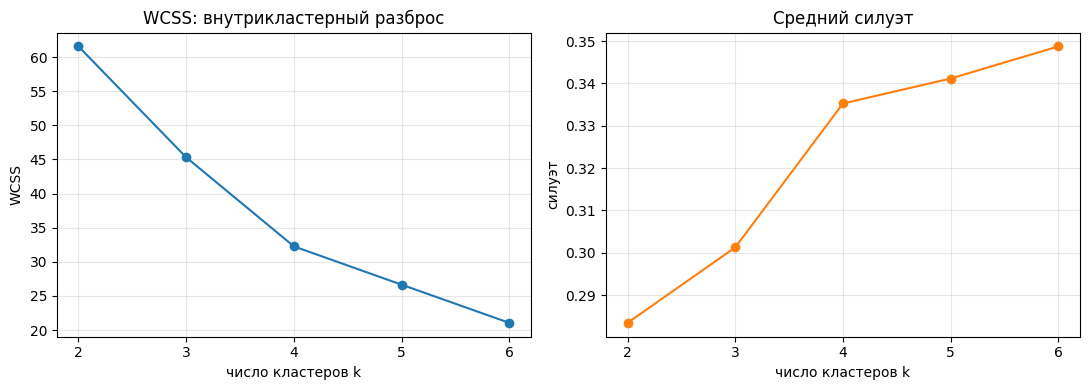

Выбрано k = 4
  1: USA, JPN, DEU, KOR, GBR, NLD, AUS, FRA, CAN
  2: MEX, MYS, SAU, ITA, CHN, ARE, POL, IND, ESP, TUR
  3: PHL, THA, VNM, EGY, IRQ
  4: BEL, ISR, CHE, AUT, DNK, SWE


In [7]:
# Рассчитай validation для k от 2 до 6
# Выбери SELECTED_K и создай final_model и final_clustered
validation_rows = []
for k in range(2, 7):
    model_k = KMeans(n_clusters=k, n_init=30, random_state=42)
    labels_k = model_k.fit_predict(z_scores)
    validation_rows.append({"k": k, "WCSS": model_k.inertia_, "Силуэт": silhouette_score(z_scores, labels_k)})
validation = pd.DataFrame(validation_rows)
display(validation)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(validation["k"], validation["WCSS"], marker="o")
axes[0].set_title("WCSS: внутрикластерный разброс")
axes[0].set_xlabel("число кластеров k")
axes[0].set_ylabel("WCSS")
axes[1].plot(validation["k"], validation["Силуэт"], marker="o", color="tab:orange")
axes[1].set_title("Средний силуэт")
axes[1].set_xlabel("число кластеров k")
axes[1].set_ylabel("силуэт")
for ax in axes:
    ax.set_xticks(validation["k"])
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

SELECTED_K = 4
final_model = KMeans(n_clusters=SELECTED_K, n_init=30, random_state=42)
final_raw = final_model.fit_predict(z_scores)

final_clustered = analysis_data.copy()
final_clustered["Метка KMeans"] = final_raw
final_order = final_clustered.groupby("Метка KMeans")["Логарифм импорта"].mean().sort_values(ascending=False).index
final_renumber = {old: new for new, old in enumerate(final_order, start=1)}
final_clustered["Кластер"] = final_clustered["Метка KMeans"].map(final_renumber)

print(f"Выбрано k = {SELECTED_K}")
final_members = final_clustered.sort_values("Импорт товара, млн долл", ascending=False).groupby("Кластер")["ISO3"].apply(", ".join)
for cluster, countries in final_members.items():
    print(f"  {cluster}: {countries}")

**Что видим.** WCSS быстро падает до k = 4 (61,6 → 45,3 → 32,3), а дальше медленнее (26,7 и 21,1). Силуэт сильнее всего прибавляет при переходе к k = 4 (0,301 → 0,335), потом растёт едва-едва. Поэтому берём k = 4. По содержанию это тоже лучше трёх групп: разнородный третий кластер распался на бедные рынки без роста (Филиппины, Таиланд, Вьетнам, Египет, Ирак) и небольшие богатые рынки (Бельгия, Израиль, Швейцария, Австрия, Дания, Швеция).

### **[Красный, 1 балл]** Пункт 2г. Устойчивость к логарифмированию импорта

Проверь, зависит ли найденное разбиение от способа подготовки импорта. Построй альтернативную модель с тем же `SELECTED_K`, но используй исходный импорт вместо его логарифма. Стандартизируй новый набор признаков, получи `alternative_labels`, рассчитай скорректированный индекс Рэнда `ARI` и составь таблицу переходов через `pd.crosstab()`. Сохрани оба результата: по ним в TeX ты определишь, какие группы устойчивы, а какие зависят от преобразования признака.

**Что получить на выходе.** Альтернативные метки, число `ARI` и таблицу `transition_table`.

**Пример вывода.**

    Adjusted Rand Index: [значение]

| Базовый кластер / альтернативный | 1 | 2 | 3 |
|---:|---:|---:|---:|
| 1 | [Число] | [Число] | [Число] |


In [8]:
# Построй альтернативное разбиение без логарифма
# Рассчитай ARI и transition_table
ALT_FEATURES = ["Импорт товара, млн долл", "Рост импорта, %", "Доход на душу, тыс долл"]
alt_scaler = StandardScaler()
alt_z = alt_scaler.fit_transform(analysis_data[ALT_FEATURES])

alt_model = KMeans(n_clusters=SELECTED_K, n_init=30, random_state=42)
alt_raw = alt_model.fit_predict(alt_z)

# Нумеруем так же, как в базовой модели: по убыванию среднего импорта
alt_frame = analysis_data[["ISO3", "Импорт товара, млн долл"]].copy()
alt_frame["Метка KMeans"] = alt_raw
alt_order = alt_frame.groupby("Метка KMeans")["Импорт товара, млн долл"].mean().sort_values(ascending=False).index
alt_renumber = {old: new for new, old in enumerate(alt_order, start=1)}
alternative_labels = alt_frame["Метка KMeans"].map(alt_renumber).to_numpy()

ARI = adjusted_rand_score(final_clustered["Кластер"], alternative_labels)
print(f"Adjusted Rand Index: {ARI:.3f}")

transition_table = pd.crosstab(
    final_clustered["Кластер"], alternative_labels,
    rownames=["Базовый кластер"], colnames=["Альтернативный"],
)
display(transition_table)

# Номера двух моделей не обязаны совпадать, поэтому смотрим состав альтернативных групп целиком
alt_members = pd.Series(alternative_labels, index=analysis_data["ISO3"])
print("Состав альтернативных кластеров (без логарифма импорта):")
for cluster in sorted(alt_members.unique()):
    print(f"  {cluster}: {', '.join(alt_members[alt_members == cluster].index)}")

Adjusted Rand Index: 0.620


Альтернативный,1,2,3,4
Базовый кластер,,,,
1,1,2,6,0
2,0,0,0,10
3,0,5,0,0
4,0,0,6,0


Состав альтернативных кластеров (без логарифма импорта):
  1: USA
  2: JPN, KOR, PHL, THA, VNM, EGY, IRQ
  3: DEU, GBR, NLD, AUS, FRA, CAN, BEL, ISR, CHE, AUT, DNK, SWE
  4: MEX, MYS, SAU, ITA, CHN, ARE, POL, IND, ESP, TUR


**Что видим.** ARI = 0,62: разбиения с логарифмом и без него заметно совпадают, но не полностью. Устойчивы две группы: быстро растущий кластер 2 целиком перешёл в одну альтернативную группу, бедные рынки кластера 3 тоже держатся вместе. От логарифма зависит крупный кластер 1: без него США выделяются в группу из одной страны, Япония и Корея уходят к бедным рынкам, а остальные смешиваются с небольшими богатыми странами из кластера 4. Получается, граница между крупными и небольшими богатыми рынками держится на том, как мы считаем импорт.

## **[Чёрный, 3 балла + 1 бонусный балл]** Задание 3. Содержание кластеров и итог для TeX

### **[Чёрный, 1 балл]** Пункт 3а. Представители и удалённые страны

Перейди от среднего профиля к отдельным странам. Для каждого рынка рассчитай расстояние до назначенного центра итоговой модели. В каждом кластере найди ближайшую к центру и наиболее удалённую страну, затем сохрани их в таблицу `representatives`. Таблица должна позволить тебе выбрать примеры для описания групп и проверить, насколько разные страны оказались внутри одного кластера.

**Что получить на выходе.** Таблицу расстояний `country_distances` и таблицу `representatives`.

**Пример вывода.**

| Кластер | Ближайшая страна | Расстояние | Наиболее удалённая страна | Расстояние |
|---:|---|---:|---|---:|
| [Номер] | [ISO3] | [Значение] | [ISO3] | [Значение] |


In [9]:
# Рассчитай country_distances и representatives
# transform() даёт расстояние от каждой страны до каждого центра; берём только до своего
all_distances = final_model.transform(z_scores)
own_distance = all_distances[np.arange(len(final_raw)), final_raw]

country_distances = final_clustered[["ISO3", "Страна", "Кластер"]].copy()
country_distances["Расстояние до центра"] = own_distance
country_distances = country_distances.sort_values(["Кластер", "Расстояние до центра"]).reset_index(drop=True)
display(country_distances)

nearest = country_distances.loc[country_distances.groupby("Кластер")["Расстояние до центра"].idxmin()]
farthest = country_distances.loc[country_distances.groupby("Кластер")["Расстояние до центра"].idxmax()]
representatives = pd.DataFrame({
    "Кластер": nearest["Кластер"].to_numpy(),
    "Ближайшая страна": nearest["ISO3"].to_numpy(),
    "Расстояние (ближ.)": nearest["Расстояние до центра"].to_numpy(),
    "Наиболее удалённая страна": farthest["ISO3"].to_numpy(),
    "Расстояние (удал.)": farthest["Расстояние до центра"].to_numpy(),
})
display(representatives)

# Чем удалённые страны отличаются от центра своей группы: разница z-оценок по каждому признаку
centers_z = pd.DataFrame(final_model.cluster_centers_, columns=FEATURES)
far_rows = []
for _, row in representatives.iterrows():
    iso = row["Наиболее удалённая страна"]
    raw_label = final_clustered.loc[final_clustered["ISO3"] == iso, "Метка KMeans"].iloc[0]
    diff = z_scores.loc[iso] - centers_z.loc[raw_label]
    far_rows.append({
        "Кластер": row["Кластер"],
        "Страна": iso,
        **diff.round(2).to_dict(),
        "Сильнее всего отличается": diff.abs().idxmax(),
    })
far_profile = pd.DataFrame(far_rows)
display(far_profile)

,ISO3,Страна,Кластер,Расстояние до центра
0,GBR,United Kingdom,1,0.317
1,DEU,Germany,1,0.342
2,NLD,Netherlands,1,0.700
3,CAN,Canada,1,0.777
4,FRA,France,1,0.804
5,AUS,Australia,1,1.004
6,KOR,South Korea,1,1.082
7,JPN,Japan,1,1.083
8,USA,United States,1,2.231
9,CHN,China,2,0.442


,Кластер,Ближайшая страна,Расстояние (ближ.),Наиболее удалённая страна,Расстояние (удал.)
0,1,GBR,0.317,USA,2.231
1,2,CHN,0.442,IND,2.194
2,3,THA,0.235,VNM,1.417
3,4,AUT,0.542,CHE,1.497


,Кластер,Страна,Логарифм импорта,"Рост импорта, %","Доход на душу, тыс долл",Сильнее всего отличается
0,1,USA,1.930,-0.100,1.110,Логарифм импорта
1,2,IND,-0.080,2.040,-0.810,"Рост импорта, %"
2,3,VNM,0.070,-1.420,-0.000,"Рост импорта, %"
3,4,CHE,0.310,0.130,1.460,"Доход на душу, тыс долл"


**Что видим.** Самые типичные страны групп: Великобритания для кластера 1 (0,32 от центра), Китай для кластера 2 (0,44), Таиланд для кластера 3 (0,24) и Австрия для кластера 4 (0,54). Дальше всех от своих центров США (2,23) и Индия (2,19): по размеру импорта и по темпу роста они такие одни, а в группы попали как ближайшие. Поэтому называть США типичным крупным рынком, а Индию типичным растущим нельзя. По разнице с центром видно, чем выделяются крайние страны: у США — импортом (на 1,93 стандартного отклонения выше центра), у Индии — ростом (+2,04), у Вьетнама — падением импорта (−1,42), у Швейцарии — доходом (+1,46).

### **[Чёрный, 1 балл]** Пункт 3б. Размер и динамика групп рынков

Сравни группы не только по средней стране, но и по их совокупному масштабу. Для каждого итогового кластера рассчитай число стран, суммарный импорт, долю в импорте всей выборки, медианный рост и медианный доход. Сохрани результат в `cluster_summary`. Не своди показатели в единый балл: таблица нужна как основание для содержательного сопоставления в TeX.

**Что получить на выходе.** Таблицу `cluster_summary`.

**Пример вывода.**

| Кластер | Стран | Суммарный импорт | Доля выборки, % | Медианный рост | Медианный доход |
|---:|---:|---:|---:|---:|---:|
| [Номер] | [Число] | [Значение] | [Значение] | [Значение] | [Значение] |


In [10]:
# Собери cluster_summary через groupby().agg().
cluster_summary = final_clustered.groupby("Кластер").agg(
    Стран=("ISO3", "count"),
    **{
        "Суммарный импорт, млн долл": ("Импорт товара, млн долл", "sum"),
        "Медианный рост, %": ("Рост импорта, %", "median"),
        "Медианный доход, тыс долл": ("Доход на душу, тыс долл", "median"),
    },
)
total_import = cluster_summary["Суммарный импорт, млн долл"].sum()
cluster_summary.insert(2, "Доля выборки, %", cluster_summary["Суммарный импорт, млн долл"] / total_import * 100)
display(cluster_summary)
print(f"Импорт всей выборки: {total_import:,.0f} млн долл.")

,Стран,"Суммарный импорт, млн долл","Доля выборки, %","Медианный рост, %","Медианный доход, тыс долл"
Кластер,,,,,
1,9,"8,481.196",61.846,3.424,57.602
2,10,"2,976.920",21.708,14.798,23.510
3,5,"1,041.237",7.593,-0.619,5.066
4,6,"1,214.135",8.854,3.915,63.032


Импорт всей выборки: 13,713 млн долл.


**Что видим.** Кластер 1 из 9 стран даёт 61,8% импорта всей выборки, но растёт медленно (медиана 3,4% в год). Кластер 2 — 21,7% импорта и самый быстрый рост, медиана 14,8%. Бедные рынки кластера 3 (7,6% импорта) в медиане даже сокращают ввоз, а небольшие богатые страны кластера 4 дают 8,9%. Выходит, основные деньги сейчас в первом кластере, а прирост во втором.

### **[Чёрный, 1 балл]** Пункт 3в. Прямое сопоставление двух кластеров

Выбери два итоговых кластера, которые имеет смысл сопоставить в рамках твоего товара, и запиши их номера в `CASE_CLUSTERS`. Для каждого выведи число стран, средний импорт, рост и доход. Отдельно выведи из `representatives` ближайшую к центру и наиболее удалённую страну. Затем рассчитай разности числовых показателей как «первый кластер минус второй» и сохрани итог в `cluster_comparison`. По этой таблице в TeX сформулируй для каждой группы следующий исследовательский вопрос и укажи, каких данных не хватает для сравнения экспортных направлений.

**Что получить на выходе.** Таблицу `cluster_comparison` с двумя кластерами и столбцом разностей; строки `representatives` для выбранных кластеров.

**Пример вывода.**

| Показатель | Кластер A | Кластер B | Разность A–B |
|---|---:|---:|---:|
| Число стран | [Значение] | [Значение] | [Разность] |
| Средний импорт | [Значение] | [Значение] | [Разность] |
| Средний рост | [Значение] | [Значение] | [Разность] |
| Средний доход | [Значение] | [Значение] | [Разность] |


In [11]:
# Выбери CASE_CLUSTERS и собери cluster_comparison
CASE_CLUSTERS = [1, 2]

case_profile = final_clustered.groupby("Кластер").agg(
    **{
        "Число стран": ("ISO3", "count"),
        "Средний импорт, млн долл": ("Импорт товара, млн долл", "mean"),
        "Средний рост, %": ("Рост импорта, %", "mean"),
        "Средний доход, тыс долл": ("Доход на душу, тыс долл", "mean"),
    }
).loc[CASE_CLUSTERS].T

first_cluster, second_cluster = CASE_CLUSTERS
cluster_comparison = case_profile.rename(columns={
    first_cluster: f"Кластер {first_cluster}",
    second_cluster: f"Кластер {second_cluster}",
})
cluster_comparison[f"Разность {first_cluster}–{second_cluster}"] = (
    case_profile[first_cluster] - case_profile[second_cluster]
)
cluster_comparison.index.name = "Показатель"
display(cluster_comparison)
display(representatives[representatives["Кластер"].isin(CASE_CLUSTERS)])

Кластер,Кластер 1,Кластер 2,Разность 1–2
Показатель,,,
Число стран,9.000,10.000,-1.000
"Средний импорт, млн долл",942.355,297.692,644.663
"Средний рост, %",3.087,15.496,-12.410
"Средний доход, тыс долл",58.200,25.734,32.466


,Кластер,Ближайшая страна,Расстояние (ближ.),Наиболее удалённая страна,Расстояние (удал.)
0,1,GBR,0.317,USA,2.231
1,2,CHN,0.442,IND,2.194


**Что видим.** Сравниваем кластеры 1 и 2, потому что в них оказались все три рынка, которые мы смотрели раньше: Корея в первом, Индия и Саудовская Аравия во втором. Средний импорт страны кластера 1 больше на 645 млн долл., зато рост ниже на 12,4 процентного пункта, а доход выше на 32,5 тыс. долл. на человека. Типичные страны — Великобритания и Китай, крайние — США и Индия. Для сравнения этих групп как экспортных направлений не хватает доли России в их импорте, пошлин и запретов, логистики и цен.

### **[Чёрный, 1 бонусный балл]** Пункт 3г. Публикации к выводам

Выбери один или несколько содержательных выводов, которые твоя команда переносит в TeX. Для каждого вывода найди надёжную публикацию, которая подтверждает определение показателя, источник данных или ограничение кластерного анализа. Укажи организацию или авторов, название, год, прямую ссылку и дату обращения. Запиши, какой вывод поддерживает публикация и чего она не доказывает. Одной пары «вывод-публикация» достаточно для полного бонусного балла.

**Что должно получиться.** Таблица `source_check` из одной или нескольких строк.

| Вывод из блокнота | Источник | Год | Ссылка | Дата обращения | Что подтверждает | Чего не доказывает |
|---|---|---:|---|---|---|---|
| [Конкретный вывод] | [Организация, название] | [Год] | https://... | [Дата] | [точная связь] | [граница источника] |


In [12]:
# Создай таблицу source_check из одной или нескольких строк.
source_check = pd.DataFrame({
    "Вывод из блокнота": [
        f"Выбор k = {SELECTED_K} опирается на средний силуэт",
        f"Разбиение с логарифмом и без него совпадает с ARI = {ARI:.2f}",
        "Доход на душу — ВВП на человека в текущих долларах",
    ],
    "Источник": [
        "Rousseeuw P. J. Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. "
        "Journal of Computational and Applied Mathematics, 20, 53–65",
        "Hubert L., Arabie P. Comparing partitions. Journal of Classification, 2, 193–218",
        "World Bank, World Development Indicators: GDP per capita (current US$), NY.GDP.PCAP.CD",
    ],
    "Год": [1987, 1985, 2026],
    "Ссылка": [
        "https://doi.org/10.1016/0377-0427(87)90125-7",
        "https://doi.org/10.1007/BF01908075",
        "https://data.worldbank.org/indicator/NY.GDP.PCAP.CD",
    ],
    "Дата обращения": ["25.10.2026", "25.10.2026", "25.10.2026"],
    "Что подтверждает": [
        "Как считается силуэт: насколько страна ближе к своей группе, чем к соседней",
        "Как устроен скорректированный индекс Рэнда: 1 — полное совпадение разбиений, около 0 — совпадение на уровне случайного",
        "Определение и единицы признака дохода, который мы берём из WDI",
    ],
    "Чего не доказывает": [
        "Что найденные группы — реальные типы рынков, а не удобное деление трёх признаков",
        "Какое из двух разбиений экономически правильнее",
        "Что доход объясняет спрос именно на фанеру",
    ],
})
pd.set_option("display.max_colwidth", 120)
display(source_check)

,Вывод из блокнота,Источник,Год,Ссылка,Дата обращения,Что подтверждает,Чего не доказывает
0,Выбор k = 4 опирается на средний силуэт,Rousseeuw P. J. Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. Journal of Co...,1987,https://doi.org/10.1016/0377-0427(87)90125-7,25.10.2026,"Как считается силуэт: насколько страна ближе к своей группе, чем к соседней","Что найденные группы — реальные типы рынков, а не удобное деление трёх признаков"
1,Разбиение с логарифмом и без него совпадает с ARI = 0.62,"Hubert L., Arabie P. Comparing partitions. Journal of Classification, 2, 193–218",1985,https://doi.org/10.1007/BF01908075,25.10.2026,"Как устроен скорректированный индекс Рэнда: 1 — полное совпадение разбиений, около 0 — совпадение на уровне случайного",Какое из двух разбиений экономически правильнее
2,Доход на душу — ВВП на человека в текущих долларах,"World Bank, World Development Indicators: GDP per capita (current US$), NY.GDP.PCAP.CD",2026,https://data.worldbank.org/indicator/NY.GDP.PCAP.CD,25.10.2026,"Определение и единицы признака дохода, который мы берём из WDI",Что доход объясняет спрос именно на фанеру
